# PCA: Compressing Breast Cancer Measurements

**Family:** Unsupervised learning | **Level:** Beginner | **Dataset:** `breast_cancer` | **Runs on:** CPU, about 1 minute(s)

Find the directions of largest variance and keep the few that matter.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How PCA relates to the SVD
- How to read explained variance
- Why scaling decides the result
- How to fit PCA without leakage

**Prerequisites:**

- Distances and vectors
- Standardising features

**Skills you will have afterwards:**

- Pick settings without labels
- Check stability
- Compare with a reference labelling

## 2. Real-World Problem

**Context.** Thirty highly correlated measurements describe each tumour.

**The problem.** Compress 30 measurements into a few components that keep most variance.

**Why it matters.** Fewer, uncorrelated features simplify models and plots.

**Why machine learning.** Correlated columns carry the same information several times.

**Why this algorithm.** PCA is the standard linear compression.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### On lines and planes of closest fit to systems of points in space

- **Type:** foundational paper
- **Authors:** Pearson, K.
- **Year and venue:** 1901, Philosophical Magazine 2(11):559-572
- **DOI or URL:** https://doi.org/10.1080/14786440109462720
- **Verification:** Crossref 2026-11-17
- **Research objective:** Find the line or plane that best fits points in space.
- **Methodology:** Minimise perpendicular distances, the origin of principal components.
- **Dataset:** Geometric argument.
- **Main findings:** The best fitting line passes through the centroid along the direction of largest variance.
- **Limitations:** Linear only.

**Relationship to this notebook.** Pearson posed the problem of the line or plane of closest fit. Modern PCA computes this with the SVD. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Centre** $X$, then $X = U S V^\top$ (SVD).

**Components** are rows of $V^\top$. Scores are $XV$. Variance along component $j$ is $s_j^2/(n-1)$.

**Explained variance ratio** $= s_j^2 / \sum_i s_i^2$.

**Reconstruction.** With $m$ components $\hat X = X V_m V_m^\top$ and the error is the sum of the dropped $s_j^2$.

**Limits.** Linear only, sensitive to scale, components are hard to interpret.

## 5. Dataset Introduction

**Breast Cancer Wisconsin (Diagnostic)**, UCI, licence CC BY 4.0, DOI 10.24432/C5DW2B. 569 rows, 30 numeric features (mean, standard error and worst value of ten nucleus properties computed from digitised fine needle aspirate images). Target `malignant` (1 malignant, 0 benign). No missing values. Limits: one institution, small sample.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from ml_lab.data import load_dataset
from ml_lab.evaluation import internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "pca"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

bundle = load_dataset("breast_cancer")
X_raw = bundle.X
y_true = bundle.y          # evaluation only
print("shape:", X_raw.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
shape: (569, 30)


,source
title,Breast Cancer Wisconsin (Diagnostic)
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/17/breast+...
license,CC BY 4.0
doi,10.24432/C5DW2B
rows,569
features,30
limits,"Single institution, small sample, features com..."


## 6. Exploratory Data Analysis

We check size, missing values, label balance and feature relations. The reference labels are used for evaluation only, never for fitting. 

Rows and columns: (569, 30)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


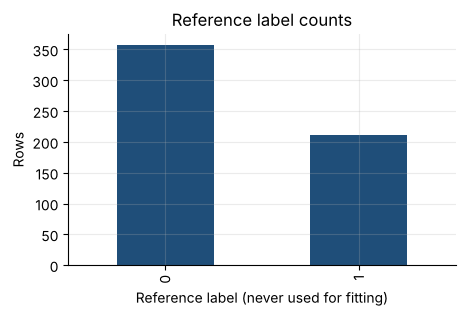

Mean absolute correlation between features: 0.382


In [2]:
print("Rows and columns:", X_raw.shape)
print("Missing values:", int(X_raw.isna().sum().sum()))
display(X_raw.describe().T.head(15).round(3))
fig, ax = plt.subplots(figsize=(5, 3))
pd.Series(y_true).value_counts().sort_index().plot.bar(ax=ax)
ax.set_xlabel("Reference label (never used for fitting)"); ax.set_ylabel("Rows"); ax.set_title("Reference label counts")
plt.show()
corr = X_raw.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print("Mean absolute correlation between features:", round(float(corr.mean()), 3))

## 7. Data Preprocessing

Split first: 70 percent of rows to fit the scaler and PCA, 30 percent held out to measure reconstruction error. This is how PCA must be used inside a prediction pipeline.

In [3]:
from sklearn.model_selection import train_test_split
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y_true, test_size=0.3, stratify=y_true, random_state=SEED)
scaler = StandardScaler().fit(X_tr)
Xs_tr, Xs_te = scaler.transform(X_tr), scaler.transform(X_te)
print(Xs_tr.shape, Xs_te.shape)

(398, 30) (171, 30)


## 8. Algorithm Implementation

### 8.1 Concept

The first component is the direction with the most variance, the second is the best direction orthogonal to it, and so on.

### 8.2 Python implementation from scratch

PCA from the SVD in four lines.

In [4]:
Xc = Xs_tr - Xs_tr.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
var_ratio_mine = S ** 2 / (S ** 2).sum()
ref = PCA().fit(Xs_tr)
print("max difference of explained variance ratio vs sklearn:", float(np.abs(var_ratio_mine - ref.explained_variance_ratio_).max()))
print("first component agrees up to sign:", bool(np.allclose(np.abs(Vt[0]), np.abs(ref.components_[0]))))

max difference of explained variance ratio vs sklearn: 2.7755575615628914e-16
first component agrees up to sign: True


### 8.3 Library implementation

scikit-learn and scipy provide tested implementations.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `n_components` | Count or variance share to keep. |
| `whiten` | Scale components to unit variance. |
| `svd_solver` | Solver. |

## 9. Model Training

PCA is fitted on training rows only. The number of components is the smallest that explains 95 percent of the training variance.

In [5]:
pca = PCA(random_state=SEED).fit(Xs_tr)
cum = np.cumsum(pca.explained_variance_ratio_)
N_COMP = int(np.searchsorted(cum, 0.95) + 1)
print("components for 95 percent variance:", N_COMP, "| for 99 percent:", int(np.searchsorted(cum, 0.99) + 1))
pca_k = PCA(N_COMP, random_state=SEED).fit(Xs_tr)
Z_tr, Z_te = pca_k.transform(Xs_tr), pca_k.transform(Xs_te)

components for 95 percent variance: 10 | for 99 percent: 17


## 10. Evaluation

Held out reconstruction error (mean squared error per feature, in standardised units) shows what the compression loses on new rows. A logistic regression on the components shows whether the label information survives. This label use is an evaluation of the compression, not part of PCA.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
recon = pca_k.inverse_transform(Z_te)
mse = float(((Xs_te - recon) ** 2).mean())
full = f1_score(y_te, LogisticRegression(max_iter=2000).fit(Xs_tr, y_tr).predict(Xs_te))
comp = f1_score(y_te, LogisticRegression(max_iter=2000).fit(Z_tr, y_tr).predict(Z_te))
METRICS = {"components": N_COMP, "variance_explained": float(cum[N_COMP - 1]), "heldout_reconstruction_MSE": mse, "F1_full_features": float(full), "F1_on_components": float(comp)}
CONFIG = {"variance_target": 0.95, "scaled": True}
EXTRA = {"cumulative_variance": [float(v) for v in cum[:10]]}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="unsupervised", algorithm="PCA", dataset="breast_cancer",
                          task="dimensionality_reduction", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

saved: /home/claude/open-python/experiments/results/pca.json


,metric
components,10.0000
variance_explained,0.9521
heldout_reconstruction_MSE,0.0502
F1_full_features,0.9600
F1_on_components,0.9600


## 11. Visualization

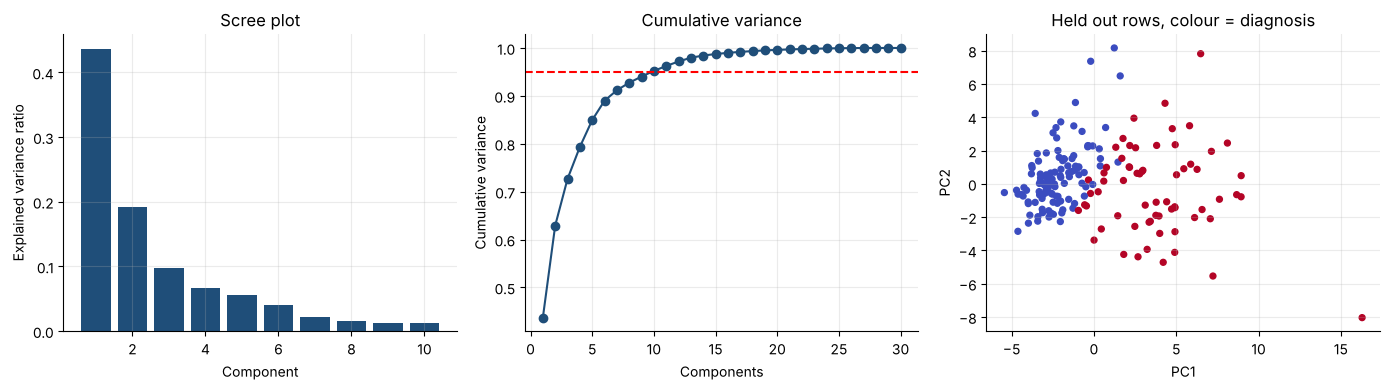

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].bar(range(1, 11), pca.explained_variance_ratio_[:10]); axes[0].set_xlabel("Component"); axes[0].set_ylabel("Explained variance ratio"); axes[0].set_title("Scree plot")
axes[1].plot(range(1, 31), cum, marker="o"); axes[1].axhline(0.95, color="red", linestyle="--"); axes[1].set_xlabel("Components"); axes[1].set_ylabel("Cumulative variance"); axes[1].set_title("Cumulative variance")
axes[2].scatter(Z_te[:, 0], Z_te[:, 1], c=y_te, cmap="coolwarm", s=18); axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2"); axes[2].set_title("Held out rows, colour = diagnosis")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "overview"); plt.show()

## 12. Interpretation

Loadings show which original measurements make up a component.

In [8]:
load = pd.DataFrame(pca.components_[:2].T, index=X_raw.columns, columns=["PC1", "PC2"])
display(load.reindex(load.PC1.abs().sort_values(ascending=False).index).head(8).round(3))

,PC1,PC2
mean concave points,0.263,-0.041
mean concavity,0.259,0.070
worst concave points,0.252,-0.006
mean compactness,0.244,0.140
worst perimeter,0.236,-0.204
worst concavity,0.228,0.115
worst radius,0.226,-0.225
mean perimeter,0.225,-0.224


## 13. Experiments and Challenges

### Experiment 1: Scaled versus raw data

Without scaling the largest scale feature dominates.

In [9]:
raw = PCA().fit(X_tr.values)
print("variance share of PC1, raw:", round(float(raw.explained_variance_ratio_[0]), 3), "| scaled:", round(float(pca.explained_variance_ratio_[0]), 3))
print("largest loading raw PC1:", X_raw.columns[np.abs(raw.components_[0]).argmax()])

variance share of PC1, raw: 0.981 | scaled: 0.437
largest loading raw PC1: worst area


### Experiment 2: Reconstruction error against components

Held out error as components increase.

In [10]:
for m in [1, 2, 5, 10, 20, 30]:
    p = PCA(m, random_state=SEED).fit(Xs_tr)
    print(m, round(float(((Xs_te - p.inverse_transform(p.transform(Xs_te))) ** 2).mean()), 4))

1 0.5139
2 0.342
5 0.1518
10 0.0502
20 0.0064
30 0.0


### Experiment 3: Leakage check

Fitting PCA on all rows including the test rows makes the held out error look better.

In [11]:
leaky = PCA(5, random_state=SEED).fit(np.vstack([Xs_tr, Xs_te]))
clean = PCA(5, random_state=SEED).fit(Xs_tr)
for name, p in [("fit on train only", clean), ("fit on train and test", leaky)]:
    print(name, round(float(((Xs_te - p.inverse_transform(p.transform(Xs_te))) ** 2).mean()), 4))

fit on train only 0.1518
fit on train and test 0.1449


### Exercises for learners

1. Repeat with `SEED = 7` and report which numbers move.
2. Change the number of rows by sampling 50 percent and compare the result.
3. Add pure noise columns and watch the internal scores.

## 14. Research Discussion

Pearson's idea of closest fit corresponds to the reconstruction error computed here. The leakage experiment shows the size of the optimistic bias on this data.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use cross validated component selection, sparse PCA for readable loadings.

**Research limitations.** One dataset and one seed for the headline numbers. 

## 15. Summary and Further Reading

**Key takeaways**

- Scale first.
- Fit on training rows only.
- Components are directions, not features.

**Use cases.** Compression, denoising, visualisation, preprocessing.

**Limitations.** Linear, hard to interpret.

**Recommended next notebook.** t-SNE.

**Further reading.** See `references.md` in this folder.